# Laboratorium 6 - rekomendacje z grafem wiedzy

## Przygotowanie

 * wypakuj dataset `ml-latest-small.zip` (ten sam co w laboratorium 5)
   * więcej możesz poczytać tutaj: https://grouplens.org/datasets/movielens/
 * [opcjonalnie] utwórz wirtualne środowisko: `python3 -m venv ./recsyslab6`
 * `pip install pykeen torch numpy pandas matplotlib`

## Idea

Graf wiedzy to zbiór trójek $(h, r, t)$ - *head*, *relacja*, *tail*, np. `(u_1, positive_rating, m_296)`
albo `(m_296, has_genre, g_Crime)`. Model (np. TransE) uczy się wektorów (*embeddingów*) dla wierzchołków i relacji
tak, by prawdziwe trójki miały wysoki wynik, a losowe - niski. W TransE relacja to przesunięcie: $h + r \approx t$.

Rekomendacja to **przewidywanie krawędzi**: dla użytkownika $u$ szukamy filmów $m$ z najwyższym wynikiem trójki
$(u, \texttt{positive\_rating}, m)$. Pozostałe relacje (gatunki, rok, tagi) nie są używane wprost,
ale mogą pomóc w nauce lepszych wektorów.

## Część 1. - dane

In [1]:
from abc import ABC, abstractmethod
from dataclasses import dataclass
from typing import Dict, List, Sequence, Set, Tuple, Type

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pykeen.models import ERModel, TransE
from pykeen.training import SLCWATrainingLoop
from pykeen.triples import TriplesFactory

Triple = Tuple[str, str, str]  # (head, relation, tail)

C:\Users\piotr\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
@dataclass(frozen=True)
class Params:
    data_path: str = 'ml-latest-small'
    min_movie_ratings: int = 10  # bierzemy tylko filmy z co najmniej tyloma ocenami
    min_tag_movies: int = 3  # bierzemy tylko tagi opisujace co najmniej tyle filmow
    test_ratio: float = 0.2  # czesc ocen kazdego uzytkownika odkladana do zbioru testowego
    positive_threshold: float = 4.0  # ocena >= progu = pozytywna
    negative_threshold: float = 2.0  # ocena <= progu = negatywna, pomiedzy progami = neutralna
    embedding_dim: int = 64
    epochs: int = 50
    batch_size: int = 1024
    learning_rate: float = 0.01
    k: int = 20  # dlugosc rekomendacji
    seed: int = 42


PARAMS = Params()

Identyfikatory wierzchołków grafu mają prefiksy (`u_` - użytkownik, `m_` - film, `g_` - gatunek, `y_` - rok,
`t_` - tag), by np. gatunek *Drama* i tag *drama* nie stały się jednym wierzchołkiem.

In [29]:
def load_ratings(params: Params) -> pd.DataFrame:
    ratings = pd.read_csv(f'{params.data_path}/ratings.csv')
    counts = ratings.movieId.value_counts()
    ratings = ratings[ratings.movieId.isin(counts[counts >= params.min_movie_ratings].index)]
    return pd.DataFrame({
        'user': 'u_' + ratings.userId.astype(str),
        'movie': 'm_' + ratings.movieId.astype(str),
        'rating': ratings.rating,
    })


def load_movies(params: Params, movie_ids: Set[str]) -> pd.DataFrame:
    movies = pd.read_csv(f'{params.data_path}/movies.csv')
    movies['movie'] = 'm_' + movies.movieId.astype(str)
    movies['year'] = movies.title.str.extract(r'\((\d{4})\)\s*$')[0]  # rok z tytulu, np. 'Heat (1995)'
    movies['genres'] = movies.genres.str.split('|').apply(lambda genres: [g for g in genres if g != '(no genres listed)'])
    return movies[movies.movie.isin(movie_ids)].set_index('movie')[['title', 'genres', 'year']]


def load_tags(params: Params, movie_ids: Set[str]) -> pd.DataFrame:
    tags = pd.read_csv(f'{params.data_path}/tags.csv')
    tags = pd.DataFrame({'movie': 'm_' + tags.movieId.astype(str), 'tag': tags.tag.str.lower().str.strip()})
    tags = tags[tags.movie.isin(movie_ids)].drop_duplicates()
    counts = tags.tag.value_counts()
    return tags[tags.tag.isin(counts[counts >= params.min_tag_movies].index)]


ratings = load_ratings(PARAMS)
movies = load_movies(PARAMS, set(ratings.movie))
tags = load_tags(PARAMS, set(ratings.movie))
print(f'{len(ratings)} ocen, {ratings.user.nunique()} uzytkownikow, {len(movies)} filmow')
print(f'{tags.tag.nunique()} tagow opisujacych {tags.movie.nunique()} filmow')
movies

81116 ocen, 610 uzytkownikow, 2269 filmow
253 tagow opisujacych 682 filmow


,title,genres,year
movie,,,
m_1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]",1995
m_2,Jumanji (1995),"[Adventure, Children, Fantasy]",1995
m_3,Grumpier Old Men (1995),"[Comedy, Romance]",1995
m_5,Father of the Bride Part II (1995),[Comedy],1995
m_6,Heat (1995),"[Action, Crime, Thriller]",1995
...,...,...,...
m_174055,Dunkirk (2017),"[Action, Drama, Thriller, War]",2017
m_176371,Blade Runner 2049 (2017),[Sci-Fi],2017
m_177765,Coco (2017),"[Adventure, Animation, Children]",2017


**Podział na zbiór treningowy i testowy:** z ocen każdego użytkownika losujemy 20% do testu. Dzięki temu każdy
użytkownik ma historię w zbiorze treningowym (jest wierzchołkiem grafu) i coś do odgadnięcia w teście.

 * graf budujemy **wyłącznie** ze zbioru treningowego - inaczej model zobaczyłby odpowiedzi
 * w teście interesują nas tylko oceny **pozytywne** - to filmy, które chcielibyśmy zarekomendować
 * filmy ocenione w zbiorze treningowym (`seen`) usuwamy z rekomendacji - użytkownik już je zna

In [4]:
def split_ratings(ratings: pd.DataFrame, params: Params) -> Tuple[pd.DataFrame, pd.DataFrame]:
    test = ratings.groupby('user').sample(frac=params.test_ratio, random_state=params.seed)
    return ratings.drop(test.index), test


train_ratings, test_ratings = split_ratings(ratings, PARAMS)
seen: Dict[str, Set[str]] = train_ratings.groupby('user').movie.apply(set).to_dict()
test_positives = test_ratings[test_ratings.rating >= PARAMS.positive_threshold][['user', 'movie']]
print(f'trening: {len(train_ratings)} ocen, test: {len(test_ratings)} ocen, w tym {len(test_positives)} pozytywnych')

trening: 64889 ocen, test: 16227 ocen, w tym 8284 pozytywnych


## Część 2. - graf wiedzy

| head | relacja | tail | źródło |
|---|---|---|---|
| użytkownik `u_*` | `positive_rating` | film `m_*` | `ratings.csv`, ocena $\geq 4$ |
| użytkownik `u_*` | `neutral_rating` | film `m_*` | `ratings.csv`, ocena 2.5 - 3.5 |
| użytkownik `u_*` | `negative_rating` | film `m_*` | `ratings.csv`, ocena $\leq 2$ |
| film `m_*` | `has_genre` | gatunek `g_*` | `movies.csv`, kolumna `genres` |
| film `m_*` | `released_in` | rok `y_*` | `movies.csv`, rok z tytułu |
| film `m_*` | `has_tag` | tag `t_*` | `tags.csv` (tagi nadane przez użytkowników) |

Model bazowy korzysta tylko z ocen pozytywnych i negatywnych.

In [30]:
ALL_RELATIONS = ['positive_rating', 'neutral_rating', 'negative_rating', 'has_genre', 'released_in', 'has_tag']
BASIC_RELATIONS = ['positive_rating', 'negative_rating']


def rating_relation(rating: float, params: Params) -> str:
    if rating >= params.positive_threshold:
        return 'positive_rating'
    if rating <= params.negative_threshold:
        return 'negative_rating'
    return 'neutral_rating'


def generate_triples(ratings: pd.DataFrame, movies: pd.DataFrame, tags: pd.DataFrame,
                     relations: Sequence[str], params: Params) -> List[Triple]:
    # przetlumacz oceny, metadane filmow i tagi na trojki (head, relation, tail) zgodnie z tabela powyzej,
    # np. ('u_1', 'positive_rating', 'm_296'), ('m_296', 'has_genre', 'g_Crime')
    # generuj tylko relacje z listy relations
    
    triples = []

    for _, rating in ratings.iterrows():
        relation = rating_relation(rating['rating'], params)
        if relation in relations:
            triples.append((rating['user'], relation, rating['movie']))

    if 'has_genre' in relations:
        for movie_id, movie in movies.iterrows():
            for genre in movie['genres']:
                triples.append((movie_id, 'has_genre', f'g_{genre}'))

    if 'released_in' in relations:
        for movie_id, movie in movies.iterrows():
            triples.append((movie_id, 'released_in', f'y_{movie["year"]}'))

    if 'has_tag' in relations:
        for _, tag in tags.iterrows():
            triples.append((tag['movie'], 'has_tag', f't_{tag['tag']}'))

    return triples

In [12]:
basic_triples = generate_triples(train_ratings, movies, tags, BASIC_RELATIONS, PARAMS)
pd.Series([relation for _, relation, _ in basic_triples]).value_counts()

positive_rating    33139
negative_rating     7534
Name: count, dtype: int64

## Część 3. - trening modelu

Model uczy się odróżniać trójki z grafu od **losowo zepsutych** (*negative sampling*: w prawdziwej trójce
podmieniamy head lub tail na losowy wierzchołek). Funkcja straty mierzy, jak słabo model je rozróżnia.

Korzystamy bezpośrednio z pętli treningowej PyKEEN zamiast `pipeline()` - `pipeline` dodatkowo dzieli trójki
na trening/walidację/test i liczy metryki przewidywania krawędzi, a my oceniamy rekomendacje własnymi metrykami
na odłożonych ocenach.

In [13]:
import torch
print(torch.cuda.is_available())

True


In [16]:
@dataclass
class TrainedModel:
    model: ERModel
    triples_factory: TriplesFactory  # mapowanie etykiet wierzcholkow i relacji na indeksy
    losses: List[float]


def train_model(triples: List[Triple], model_class: Type[ERModel], params: Params, **model_kwargs) -> TrainedModel:
    triples_factory = TriplesFactory.from_labeled_triples(np.array(triples))
    model = model_class(triples_factory=triples_factory, embedding_dim=params.embedding_dim,
                        random_seed=params.seed, **model_kwargs)
    model = model.to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    training_loop = SLCWATrainingLoop(model=model, triples_factory=triples_factory,
                                      optimizer='Adam', optimizer_kwargs={'lr': params.learning_rate})
    losses = training_loop.train(triples_factory=triples_factory, num_epochs=params.epochs,
                                 batch_size=params.batch_size, use_tqdm_batch=False)
    return TrainedModel(model, triples_factory, losses)


transe = train_model(basic_triples, TransE, PARAMS)

Training epochs on cuda:0: 100%|██████████| 50/50 [00:23<00:00,  2.13epoch/s, loss=0.152, prev_loss=0.148]


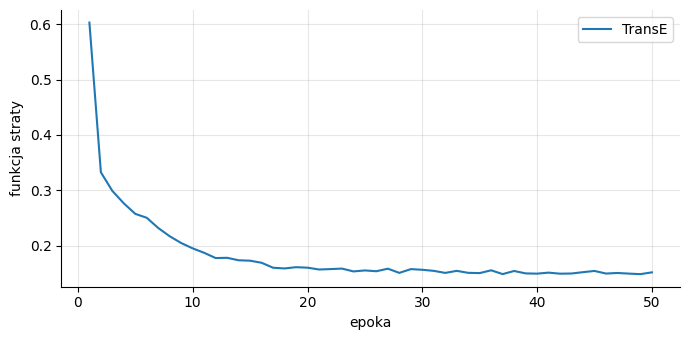

In [17]:
def plot_losses(trained: Dict[str, TrainedModel]):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for name, model in trained.items():
        ax.plot(range(1, len(model.losses) + 1), model.losses, label=name)
    ax.set_xlabel('epoka')
    ax.set_ylabel('funkcja straty')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend()
    plt.tight_layout()
    plt.show()


# jesli strata wciaz wyraznie spada - zwieksz liczbe epok
# (wartosci straty roznych modeli i grafow nie sa porownywalne - patrzymy tylko, czy krzywa sie wyplaszczyla)
plot_losses({'TransE': transe})

## Część 4. - rekomendacje

Każdy rekomender zwraca listę `k` identyfikatorów filmów (najlepszy pierwszy), z pominięciem filmów już ocenionych.
Do porównania potrzebujemy punktów odniesienia: rekomendacji **losowej** i **najpopularniejszych** filmów
(najwięcej ocen pozytywnych w zbiorze treningowym). Model, który nie bije popularności, nie jest wart wdrożenia.

In [18]:
def top_k(scores: pd.Series, exclude: Set[str], k: int) -> List[str]:
    # zwroc k etykiet (indeks scores) z najwyzszym wynikiem, pomijajac etykiety z exclude
    # remisy rozstrzygamy kolejnoscia w scores (sortowanie stabilne)
    return scores[~scores.index.isin(exclude)].nlargest(k).index.tolist()
    


class Recommender(ABC):
    name: str

    @abstractmethod
    def recommend(self, user: str, k: int) -> List[str]:
        ...


class RandomRecommender(Recommender):
    name = 'losowy'

    def __init__(self, movie_ids: Sequence[str], seen: Dict[str, Set[str]], seed: int):
        self.movie_ids = pd.Index(movie_ids)
        self.seen = seen
        self.rng = np.random.default_rng(seed)

    def recommend(self, user: str, k: int) -> List[str]:
        candidates = self.movie_ids.difference(self.seen.get(user, set()))
        return self.rng.choice(candidates, min(k, len(candidates)), replace=False).tolist()


class PopularityRecommender(Recommender):
    name = 'popularność'

    def __init__(self, train_ratings: pd.DataFrame, seen: Dict[str, Set[str]], params: Params):
        # wynik filmu = liczba ocen pozytywnych w zbiorze treningowym
        self.popularity = train_ratings[train_ratings['rating'] >= params.positive_threshold].groupby('movie').size()
        self.seen = seen

    def recommend(self, user: str, k: int) -> List[str]:

        return top_k(self.popularity, self.seen.get(user, set()), k)

**Rekomender grafowy** - dla użytkownika liczymy wynik trójek $(u, \texttt{positive\_rating}, t)$ dla **każdego**
wierzchołka $t$ (`tail_scores`). Wśród wyników są też użytkownicy, gatunki czy tagi - do rekomendacji bierzemy
tylko filmy. Użytkownik spoza grafu (np. bez żadnej oceny pozytywnej/negatywnej w treningu) dostaje pustą listę.

In [19]:
def tail_scores(trained: TrainedModel, head: str, relation: str) -> pd.Series:
    factory = trained.triples_factory
    batch = torch.tensor([[factory.entity_to_id[head], factory.relation_to_id[relation]]])
    scores = trained.model.predict_t(batch)[0].detach().cpu().numpy()
    return pd.Series(scores, index=[factory.entity_id_to_label[i] for i in range(factory.num_entities)])


class KnowledgeGraphRecommender(Recommender):
    def __init__(self, name: str, trained: TrainedModel, seen: Dict[str, Set[str]]):
        self.name = name
        self.trained = trained
        self.seen = seen
        self.movie_ids = [label for label in trained.triples_factory.entity_to_id if label.startswith('m_')]

    def scores(self, user: str) -> pd.Series:
        # wyniki relacji positive_rating dla wszystkich filmow (tylko filmow!)
        return tail_scores(self.trained, user, 'positive_rating')[self.movie_ids]

    def recommend(self, user: str, k: int) -> List[str]:
        # pamietaj o uzytkownikach spoza grafu i o filmach juz ocenionych
        if user not in self.trained.triples_factory.entity_to_id:
            return []
        return top_k(self.scores(user), self.seen.get(user, set()), k)

In [20]:
def show_movies(movie_ids: Sequence[str]) -> pd.DataFrame:
    return movies.loc[list(movie_ids), ['title', 'genres']]


def describe_user(user: str, recommender: Recommender, k: int):
    history = train_ratings[train_ratings.user == user].sort_values('rating', ascending=False)
    print(f'{user}: {len(history)} ocen w zbiorze treningowym, najwyzej ocenione:')
    display(show_movies(history.movie[:10]).assign(rating=history.rating[:10].values))
    print(f'rekomendacja ({recommender.name}):')
    display(show_movies(recommender.recommend(user, k)))


describe_user('u_1', KnowledgeGraphRecommender('TransE', transe, seen), 10)

u_1: 169 ocen w zbiorze treningowym, najwyzej ocenione:


,title,genres,rating
movie,,,
m_50,"Usual Suspects, The (1995)","[Crime, Mystery, Thriller]",5.0
m_151,Rob Roy (1995),"[Action, Drama, Romance, War]",5.0
m_47,Seven (a.k.a. Se7en) (1995),"[Mystery, Thriller]",5.0
m_101,Bottle Rocket (1996),"[Adventure, Comedy, Crime, Romance]",5.0
m_527,Schindler's List (1993),"[Drama, War]",5.0
m_362,"Jungle Book, The (1994)","[Adventure, Children, Romance]",5.0
m_231,Dumb & Dumber (Dumb and Dumber) (1994),"[Adventure, Comedy]",5.0
m_216,Billy Madison (1995),[Comedy],5.0
m_163,Desperado (1995),"[Action, Romance, Western]",5.0


rekomendacja (TransE):


,title,genres
movie,,
m_858,"Godfather, The (1972)","[Crime, Drama]"
m_1125,"Return of the Pink Panther, The (1975)","[Comedy, Crime]"
m_2791,Airplane! (1980),[Comedy]
m_1270,Back to the Future (1985),"[Adventure, Comedy, Sci-Fi]"
m_589,Terminator 2: Judgment Day (1991),"[Action, Sci-Fi]"
m_2064,Roger & Me (1989),[Documentary]
m_3698,"Running Man, The (1987)","[Action, Sci-Fi]"
m_1240,"Terminator, The (1984)","[Action, Sci-Fi, Thriller]"
m_380,True Lies (1994),"[Action, Adventure, Comedy, Romance, Thriller]"


## Część 5. - metryki

Dla każdej pozytywnej oceny testowej $(u, m)$ generujemy rekomendację $R_u$ długości $k$ i sprawdzamy,
na której pozycji (licząc od 1) jest film $m$:

 * **HitRatio@k** - odsetek ocen testowych, dla których $m \in R_u$
 * **MRR@k** (*Mean Reciprocal Rank*) - średnia z $\frac{1}{\text{pozycja } m \text{ w } R_u}$, a 0, gdy $m \notin R_u$;
   nagradza trafienia na początku listy

MRR zastępuje znaną z poprzednich edycji średnią pozycję trafień - ta liczona była tylko po trafieniach,
więc model z jednym trafieniem na 1. pozycji wypadał lepiej niż model ze stoma trafieniami na pozycjach 1-5.

In [21]:
def hit(recommendation: Sequence[str], movie: str) -> float:
    # 1, jesli film jest w rekomendacji, 0 w przeciwnym razie
    return 1.0 if movie in recommendation else 0.0


def reciprocal_rank(recommendation: Sequence[str], movie: str) -> float:
    # 1 / pozycja filmu w rekomendacji (liczona od 1), 0 jesli filmu nie ma
    try:
        return 1.0 / (recommendation.index(movie) + 1)
    except ValueError:
        return 0.0

Rekomendację generujemy **raz na użytkownika** (nie raz na ocenę testową) - użytkownik ma średnio kilkanaście
pozytywnych ocen w teście, więc to kilkanaście razy szybciej.

In [48]:
def evaluate(recommender: Recommender, test_positives: pd.DataFrame, k: int) -> pd.DataFrame:
    recommendations = {user: recommender.recommend(user, k) for user in test_positives.user.unique()}
    pairs = list(zip(test_positives.user, test_positives.movie))
    return pd.DataFrame({
        'recommender': recommender.name,
        'hit_ratio': [hit(recommendations[user], movie) for user, movie in pairs],
        'mrr': [reciprocal_rank(recommendations[user], movie) for user, movie in pairs],
    })


baselines: List[Recommender] = [
    RandomRecommender(movies.index, seen, PARAMS.seed),
    PopularityRecommender(train_ratings, seen, PARAMS),
    KnowledgeGraphRecommender('TransE (bazowy)', transe, seen),
]
results = pd.concat([evaluate(recommender, test_positives, PARAMS.k) for recommender in baselines])
results.groupby('recommender', sort=False).mean().round(4)

,hit_ratio,mrr
recommender,,
losowy,0.0107,0.0019
popularność,0.1539,0.0390
TransE (bazowy),0.1375,0.0327


## Część 6. - eksperymenty

Wytrenowaliśmy model bazowy (TransE na relacjach `positive_rating` i `negative_rating`), umiemy generować
rekomendacje i oceniać ich jakość. Teraz sprawdzimy, co może ją poprawić.

Porównaj model bazowy z **dwoma** innymi podejściami. Wybierz dwie spośród poniższych modyfikacji
lub zaproponuj własną:

1. **Zmiana modelu** - zamiast TransE użyj np. TransH, TransR, RotatE, DistMult, ComplEx albo RESCAL
   ([lista modeli PyKEEN](https://pykeen.readthedocs.io/en/stable/reference/models.html)).
   Możesz też dostroić hiperparametry (`embedding_dim`, `epochs`, `learning_rate` - `replace(PARAMS, epochs=100)`).
2. **Rozszerzenie grafu** - dodaj oceny neutralne, gatunki, rok premiery, tagi. Nawet jeśli relacja nie jest
   używana do rekomendacji, może poprawić wytrenowane wektory. Pamiętaj, by rekomendować wyłącznie filmy.
3. **Zmiana sposobu rekomendacji** - zamiast samego wyniku `positive_rating` możesz np. karać filmy z wysokim
   wynikiem `negative_rating`, filtrować kandydatów po metadanych (np. ulubionych gatunkach użytkownika)
   albo łączyć wynik modelu z popularnością. Wystarczy nadpisać `scores` lub `recommend` w podklasie
   `KnowledgeGraphRecommender`.

Każde podejście dopisz do listy `experiments` - podsumowanie w Części 7. wygeneruje się automatycznie.

In [ ]:
from pykeen.models import ComplEx

better_triples = generate_triples(train_ratings, movies, tags, ALL_RELATIONS, PARAMS)

better_params = Params(embedding_dim=128, epochs=100, batch_size=2048, learning_rate=0.005)

complex = train_model(better_triples, ComplEx, better_params)

Training epochs on cuda:0: 100%|██████████| 100/100 [01:57<00:00,  1.18s/epoch, loss=0.255, prev_loss=0.258]


In [39]:
complex_base_relations = train_model(basic_triples, ComplEx, better_params)

Training epochs on cuda:0: 100%|██████████| 100/100 [00:51<00:00,  1.95epoch/s, loss=0.304, prev_loss=0.31]


In [ ]:
from pykeen.models import RESCAL

rescal = train_model(better_triples, RESCAL, better_params)

Training epochs on cuda:0: 100%|██████████| 100/100 [03:35<00:00,  2.15s/epoch, loss=1.01, prev_loss=1.02]


In [40]:
rescal_base_relations = train_model(basic_triples, RESCAL, better_params)

Training epochs on cuda:0: 100%|██████████| 100/100 [01:40<00:00,  1.00s/epoch, loss=5.41, prev_loss=5.56]


In [47]:
from pykeen.models import DistMult

distmult = train_model(better_triples, DistMult, better_params)

Training epochs on cuda:0: 100%|██████████| 100/100 [00:56<00:00,  1.78epoch/s, loss=0.35, prev_loss=0.35] 


In [49]:
experiments: List[Recommender] = [
    complex_recommender := KnowledgeGraphRecommender('ComplEx', complex, seen),
    complex_base_recommender := KnowledgeGraphRecommender('ComplExBasicTriples', complex_base_relations, seen),
    rescal_recommender := KnowledgeGraphRecommender('RESCAL', rescal, seen),
    rescal_base_recommender := KnowledgeGraphRecommender('RESCALBasicTriples', rescal_base_relations, seen),
    distmult_recommender := KnowledgeGraphRecommender('DistMult', distmult, seen)
]
results = pd.concat([results] + [evaluate(recommender, test_positives, PARAMS.k) for recommender in experiments])
results.groupby('recommender', sort=False).mean().round(4)

,hit_ratio,mrr
recommender,,
losowy,0.0107,0.0019
popularność,0.1539,0.0390
TransE (bazowy),0.1375,0.0327
ComplEx,0.0641,0.0136
ComplExBasicTriples,0.0565,0.0124
RESCAL,0.0088,0.0013
RESCALBasicTriples,0.0711,0.0098
DistMult,0.2022,0.0479


## Część 7. - podsumowanie

Słupki - średnia po pozytywnych ocenach testowych, wąsy - 95% przedział ufności średniej
($\pm 1.96 \cdot \frac{s}{\sqrt{n}}$). Szare - punkty odniesienia, niebieski - model bazowy, pomarańczowe - eksperymenty.

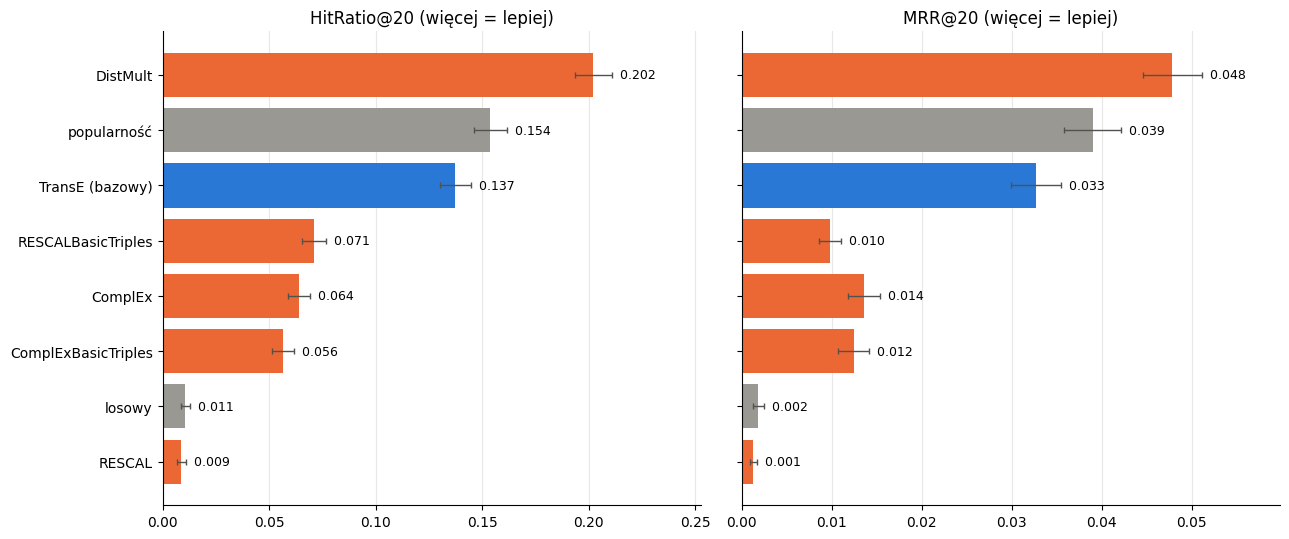

In [50]:
METRICS = {
    'hit_ratio': f'HitRatio@{PARAMS.k}',
    'mrr': f'MRR@{PARAMS.k}',
}
COLORS = {'odniesienie': '#9a9893', 'bazowy': '#2a78d6', 'eksperyment': '#eb6834'}


def plot_results(results: pd.DataFrame, baselines: List[Recommender], experiments: List[Recommender]):
    kinds = {r.name: 'odniesienie' for r in baselines[:-1]}  # ostatni w baselines to model bazowy
    kinds[baselines[-1].name] = 'bazowy'
    kinds.update({r.name: 'eksperyment' for r in experiments})
    stats = results.groupby('recommender')[list(METRICS)].agg(['mean', 'sem'])
    order = stats[('hit_ratio', 'mean')].sort_values().index
    colors = [COLORS[kinds[name]] for name in order]

    fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 0.5 * len(order) + 1.5), sharey=True)
    for ax, (metric, title) in zip(axes, METRICS.items()):
        values = stats.loc[order, metric]
        ax.barh(order, values['mean'], xerr=1.96 * values['sem'], color=colors,
                error_kw={'elinewidth': 1, 'capsize': 2, 'ecolor': '#52514e'})
        for position, (value, sem) in enumerate(zip(values['mean'], values['sem'])):
            ax.text(value + 1.96 * sem, position, f'  {value:.3f}', va='center', ha='left', fontsize=9)
        ax.set_title(f'{title} (więcej = lepiej)')
        ax.set_xlim(0, values['mean'].max() * 1.25)
        ax.grid(axis='x', alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_results(results, baselines, experiments)